In [2]:
import os

for root, dirs, files in os.walk(r"C:\Users\Rashmitha R Nayak"):
    for file in files:
        if "inception" in file.lower() and file.endswith(".json"):
            print(os.path.join(root, file))

C:\Users\Rashmitha R Nayak\Downloads\brain_abnormalities_rashmi_nozip\brain_abnormalities\inceptionv4\metrics_inceptionv4_without_cv.json
C:\Users\Rashmitha R Nayak\Downloads\brain_abnormalities_rashmi_nozip\brain_abnormalities\inceptionv4\metrics_inceptionv4_with_cv.json
C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\metrics_inceptionv4_without_cv.json
C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\metrics_inceptionv4_with_cv.json
C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0001_wd0.0001.json
C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0001_wd1e-05.json
C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0003_wd0.0001.json
C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0003_wd1e-05.json
C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\

In [3]:
import json

file_path = r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0001_wd0.0001.json"

with open(file_path, "r") as f:
    data = json.load(f)

print(data)

{'mode': 'with_cv', 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'accuracy': 99.04, 'precision': 99.02, 'recall': 99.01, 'f1_score': 99.02, 'parameters_million': 41.15}


In [4]:
import json
import pandas as pd

files = [
    r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0001_wd0.0001.json",
    r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0001_wd1e-05.json",
    r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0003_wd0.0001.json",
    r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\metrics_inceptionv4_cv_lr0.0003_wd1e-05.json"
]

all_results = []

for file in files:
    with open(file, "r") as f:
        all_results.append(json.load(f))

df = pd.DataFrame(all_results)

df = df.sort_values(
    by="accuracy",
    ascending=False
).reset_index(drop=True)

print("📊 All InceptionV4 Configurations:\n")
display(df)

print("\n🏆 Best Configuration:\n")
print(df.iloc[0].to_dict())

📊 All InceptionV4 Configurations:



,mode,learning_rate,weight_decay,accuracy,precision,recall,f1_score,parameters_million
0,with_cv,0.0001,0.00010,99.04,99.02,99.01,99.02,41.15
1,with_cv,0.0003,0.00010,99.00,98.97,98.97,98.97,41.15
2,with_cv,0.0001,0.00001,98.63,98.59,98.60,98.59,41.15
3,with_cv,0.0003,0.00001,98.28,98.24,98.21,98.22,41.15



🏆 Best Configuration:

{'mode': 'with_cv', 'learning_rate': 0.0001, 'weight_decay': 0.0001, 'accuracy': 99.04, 'precision': 99.02, 'recall': 99.01, 'f1_score': 99.02, 'parameters_million': 41.15}


Using device: cuda

Epoch 1/10
→ Train Acc: 90.79%, Val Acc: 95.34%

Epoch 2/10
→ Train Acc: 97.27%, Val Acc: 98.08%

Epoch 3/10
→ Train Acc: 97.95%, Val Acc: 98.81%

Epoch 4/10
→ Train Acc: 99.40%, Val Acc: 99.73%

Epoch 5/10
→ Train Acc: 99.61%, Val Acc: 99.73%

Epoch 6/10
→ Train Acc: 99.79%, Val Acc: 99.63%

Epoch 7/10
→ Train Acc: 99.75%, Val Acc: 99.45%
 Early stopping triggered.


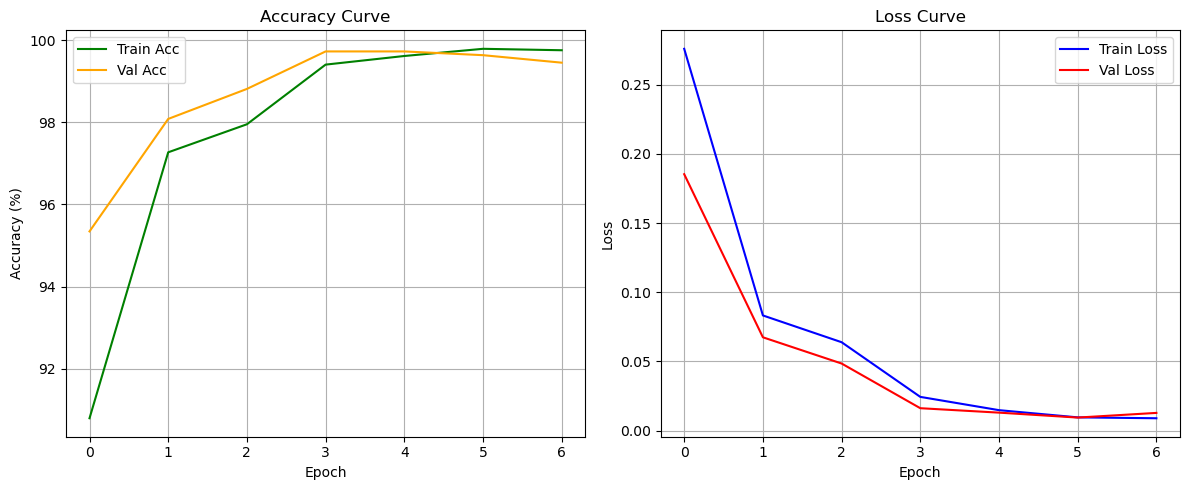


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00       300
  meningioma       0.99      1.00      0.99       200
     notumor       1.00      1.00      1.00       300
   pituitary       1.00      0.99      1.00       295

    accuracy                           1.00      1095
   macro avg       1.00      1.00      1.00      1095
weighted avg       1.00      1.00      1.00      1095



In [26]:
import os
import torch
import timm
import json
import numpy as np
import matplotlib.pyplot as plt
from torch import nn, optim
from torch.amp import GradScaler, autocast
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

#  Paths
train_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Training_256x256"
test_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"

#  Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

#  Best Hyperparameters from CV
lr = 1e-4
wd = 1e-5
batch_size = 16
EPOCHS = 10
patience = 3

#  Transforms
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

#  Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)
num_classes = len(train_dataset.classes)

#  DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

#  Create Model
def create_model(lr, wd):
    model = timm.create_model("inception_v4", pretrained=True, num_classes=num_classes)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = StepLR(optimizer, step_size=3, gamma=0.1)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, scheduler, criterion

model, optimizer, scheduler, criterion = create_model(lr, wd)
model = model.to(device)
scaler = GradScaler()

#  Training Loop
train_accuracies, val_accuracies = [], []
train_losses, val_losses = [], []
best_val_acc = 0
counter = 0

for epoch in range(EPOCHS):
    print(f"\n\033[95mEpoch {epoch+1}/{EPOCHS}\033[0m")
    
    #  Training
    model.train()
    correct, total, epoch_loss = 0, 0, 0.0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast('cuda'):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        epoch_loss += loss.item()

    train_acc = 100 * correct / total
    train_accuracies.append(train_acc)
    train_losses.append(epoch_loss / len(train_loader))

    #  Validation
    model.eval()
    correct, total, val_loss = 0, 0, 0.0
    val_preds, val_labels = [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            with autocast(device_type='cuda'):
                outputs = model(imgs)
                loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            val_loss += loss.item()
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_acc = 100 * correct / total
    val_accuracies.append(val_acc)
    val_losses.append(val_loss / len(test_loader))

    print(f"→ Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model.state_dict()
        all_preds = val_preds
        all_labels = val_labels
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(" Early stopping triggered.")
            break

    scheduler.step()

# Plot Training Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_accuracies, label='Train Acc', color='green')
plt.plot(val_accuracies, label='Val Acc', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(val_losses, label='Val Loss', color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#  Classification Report
print("\n\U0001F8BE Classification Report:")
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

#  Save Metrics
params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

metrics = {
    "mode": "without_cv",
    "accuracy": round(best_val_acc, 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}
with open("metrics_inceptionv4_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)


C:\Users\STUDENT\AppData\Local\Temp\ipykernel_17328\1249907486.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/10


C:\Users\STUDENT\AppData\Local\Temp\ipykernel_17328\1249907486.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
                                                                                                                       

→ Train Accuracy: 90.58%

Epoch 2/10


→ Train Accuracy: 97.09%

Epoch 3/10


...

→ Train Accuracy: 99.89%

Epoch 9/10


→ Train Accuracy: 99.88%

Epoch 10/10


→ Train Accuracy: 99.84%


C:\Users\STUDENT\AppData\Local\Temp\ipykernel_17328\1249907486.py:62: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
                                                                                                                       


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99       300
  meningioma       0.88      0.99      0.93       200
     notumor       1.00      0.92      0.96       300
   pituitary       0.99      1.00      0.99       295

    accuracy                           0.97      1095
   macro avg       0.97      0.98      0.97      1095
weighted avg       0.98      0.97      0.97      1095



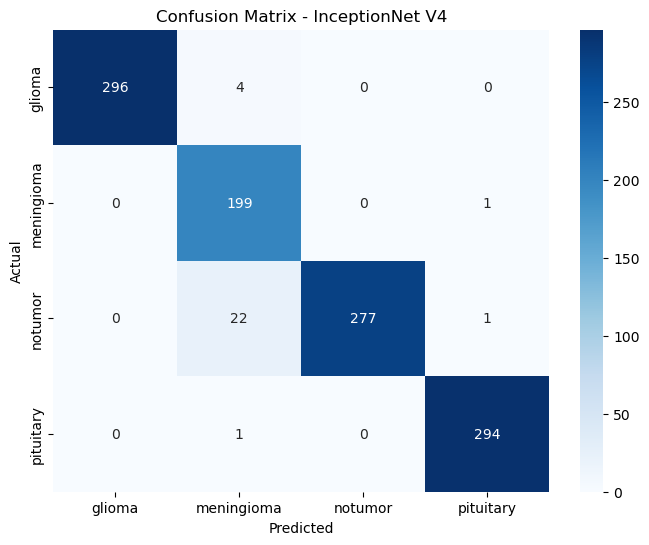

In [29]:
#  Final Training + Testing for InceptionNet V4 (Without Cross-Validation)

import torch
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import json
from tqdm import tqdm
from torch.cuda.amp import GradScaler, autocast

#  Final Training + Testing for DenseNet121 (Without Cross-Validation)


from torch.utils.data import DataLoader


#  Train on full training data
full_train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

model, optimizer, scheduler, criterion = create_model(best_config['learning_rate'], best_config['weight_decay'])
model = model.to(device)

scaler = GradScaler()
best_val_acc = 0
train_accuracies, train_losses = [], []

for epoch in range(EPOCHS):
    print(f"\n\033[95mEpoch {epoch+1}/{EPOCHS}\033[0m")
    model.train()
    correct, total, epoch_loss = 0, 0, 0.0

    for imgs, labels in tqdm(full_train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        epoch_loss += loss.item()

    train_acc = 100 * correct / total
    train_accuracies.append(train_acc)
    train_losses.append(epoch_loss / len(full_train_loader))
    print(f"→ Train Accuracy: {train_acc:.2f}%")
    scheduler.step()

#  Testing
model.eval()
correct, total = 0, 0
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating [Test]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        with autocast():
            outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

final_test_acc = 100 * correct / total

#  Classification Report
print("\n\U0001F8BE Classification Report:")
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

#  Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - InceptionNet V4")
plt.show()

# Save Metrics
params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

metrics = {
    "mode": "without_cv",
    "accuracy": round(final_test_acc, 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}

with open("metrics_inceptionv4_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)


In [6]:
test_metrics = classification_report(all_labels, all_preds, target_names=test_dataset.classes, output_dict=True)

with open("inceptionv4_test_results.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

print(" Test metrics saved to 'inceptionv4_test_results.json'")


NameError: name 'classification_report' is not defined

In [7]:
import json

with open("inceptionv4_all_cv_results.json", "r") as f:
    all_results = json.load(f)

# Get best config
best_config = sorted(all_results, key=lambda x: x['accuracy'], reverse=True)[0]
print(best_config)


{'learning_rate': 0.0001, 'weight_decay': 0.0001, 'accuracy': 99.04, 'precision': 99.02, 'recall': 99.01, 'f1_score': 99.02, 'parameters_million': 41.15}


In [8]:
import timm
import torch
from torch import nn, optim

# ✅ Use best hyperparameters
lr = best_config["learning_rate"]
wd = best_config["weight_decay"]

# ✅ Build model
model = timm.create_model("inception_v4", pretrained=True, num_classes=4)
model.to("cuda" if torch.cuda.is_available() else "cpu")

# ✅ Optimizer
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

# (Insert your training loop here...)

# ✅ Save after training
torch.save(model.state_dict(), "inceptionv4_best_model.pth")


In [9]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchvision import transforms
from timm import create_model


# ✅ Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ✅ Load InceptionV4 model
model = create_model("inception_v4", pretrained=False, num_classes=4)
model.load_state_dict(torch.load("inceptionv4_best_model.pth", map_location=device))
model = model.to(device).eval()

# ✅ Get last convolutional block
target_layer = model.features[-1]


In [10]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate_cam(self, input_tensor, class_idx=None):
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = torch.argmax(output).item()

        self.model.zero_grad()
        class_score = output[0, class_idx]
        class_score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze()
        cam = torch.clamp(cam, min=0)
        cam -= cam.min()
        cam /= cam.max()
        return cam.cpu().numpy()


In [11]:
def show_gradcam_on_image(img_tensor, cam, alpha=0.5):
    img = img_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    img = (img * 0.5 + 0.5)  # unnormalize

    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255

    overlay = heatmap * alpha + img
    overlay = np.clip(overlay, 0, 1)

    plt.imshow(overlay)
    plt.axis('off')
    plt.title("Grad-CAM")
    plt.show()


In [12]:
from torchvision import datasets, transforms

# Set your test directory path
test_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"

# Transforms (same normalization as training)
val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# Define test dataset
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transforms)


C:\Users\STUDENT\Downloads\anaconda\envs\pydl\Lib\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


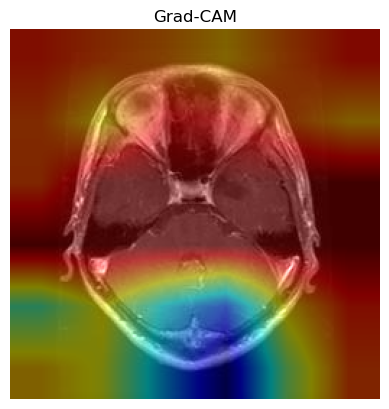

In [13]:
model = create_model("inception_v4", pretrained=False, num_classes=4)
model.load_state_dict(torch.load("inceptionv4_best_model.pth"))
model = model.to(device).eval()

# 🔍 Target last inception block
target_layer = model.features[-1]

gradcam = GradCAM(model, target_layer)

img, label = test_dataset[1]
input_tensor = img.unsqueeze(0).to(device)

cam = gradcam.generate_cam(input_tensor)
show_gradcam_on_image(img, cam)


In [14]:
!pip install grad-cam


In [17]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# -------------------------------
# ✅ Configuration
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#test_dir = r"C:\Users\STUDENT\Documents\OCTDL_Split\test"  # 🔁 Update if needed
test_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"

input_size = 224

# -------------------------------
# ✅ Load your model here
# -------------------------------
# For InceptionV4
# from timm import create_model
# model = create_model("inception_v4", pretrained=False, num_classes=4)
# model.load_state_dict(torch.load("inceptionv4_best_model.pth", map_location=device))

# For DenseNet121
# model = create_model("densenet121", pretrained=False, num_classes=4)
# model.load_state_dict(torch.load("densenetretrain_final_best.pth", map_location=device))

model = model.to(device).eval()  # Ensure loaded model is ready

# -------------------------------
# ✅ Select final conv layer
# -------------------------------
# For DenseNet121: features[-1]
# For InceptionV4: features[-1]
target_layer = model.features[-1]

# -------------------------------
# ✅ Define image transform
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], 
                         [0.229, 0.224, 0.225])
])

# -------------------------------
# ✅ Prepare test images
# -------------------------------
class_names = sorted(os.listdir(test_dir))
print("🔍 Found classes:", class_names)

# -------------------------------
# ✅ Initialize Grad-CAM
# -------------------------------
cam = GradCAM(model=model, target_layers=[target_layer], use_cuda=torch.cuda.is_available())

# -------------------------------
# 🔁 Loop over 1 image per class
# -------------------------------
for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not image_files:
        print(f"⚠️ No images found in {class_name}")
        continue

    # ✅ Load image
    img_path = os.path.join(class_path, image_files[0])
    image = Image.open(img_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)

    # ✅ Predict class
    outputs = model(input_tensor)
    pred_class = torch.argmax(outputs, dim=1).item()
    pred_class_name = class_names[pred_class]
    print(f"📸 {img_path} → Predicted: {pred_class_name}")

    # ✅ Generate Grad-CAM
    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred_class)])
    grayscale_cam = grayscale_cam[0]  # (H, W)
    rgb_img = np.array(image.resize((input_size, input_size))) / 255.0
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # ✅ Plot
    plt.figure(figsize=(6, 4))
    plt.imshow(visualization)
    plt.title(f"Grad-CAM\nTrue = {class_name}, Pred = {pred_class_name}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


Exception ignored in: <function BaseCAM.__del__ at 0x0000010E24DC1260>
Traceback (most recent call last):
  File "C:\Users\STUDENT\Downloads\anaconda\envs\pydl\Lib\site-packages\pytorch_grad_cam\base_cam.py", line 212, in __del__
    self.activations_and_grads.release()
    ^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'GradCAM' object has no attribute 'activations_and_grads'


🔍 Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


TypeError: GradCAM.__init__() got an unexpected keyword argument 'use_cuda'

🔍 Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


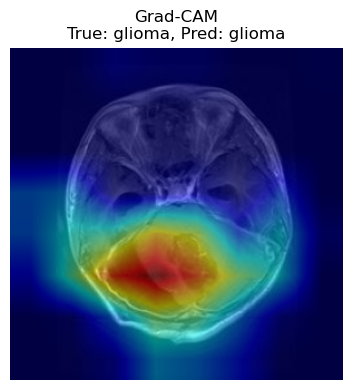

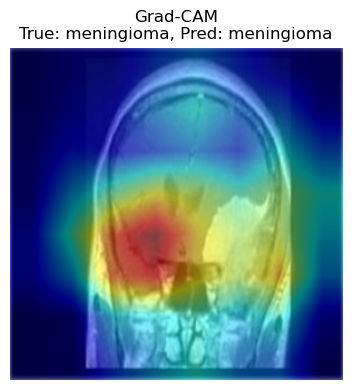

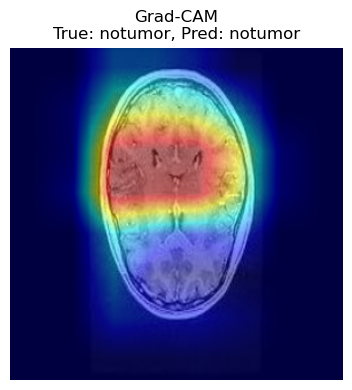

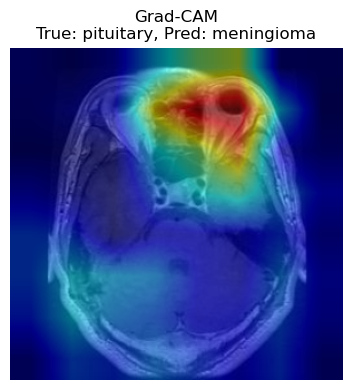

In [19]:
import os
import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import timm

# --------------------------------
# 🔧 Setup
# --------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"
input_size = 299  # for InceptionV4

# --------------------------------
# 🔍 Load InceptionV4 Model
# --------------------------------
model = timm.create_model("inception_v4", pretrained=False, num_classes=4)
model.load_state_dict(torch.load("inceptionv4_best_model.pth", map_location=device))
model = model.to(device).eval()

# Final conv layer for InceptionV4 (stem+features)
target_layer = model.features[-1]  # Usually last conv block

# --------------------------------
# 🔄 Transform (match training)
# --------------------------------
transform = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # Or ImageNet mean/std if pretrained
])

# --------------------------------
# 🏷️ Class Names
# --------------------------------
class_names = sorted(os.listdir(test_dir))
print("🔍 Found classes:", class_names)

# --------------------------------
# 🔁 Loop over 1 image from each class
# --------------------------------
for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    if not image_files:
        print(f"⚠️ No images in {class_name}")
        continue

    # Load image
    img_path = os.path.join(class_path, image_files[0])
    image = Image.open(img_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        output = model(input_tensor)
        pred_class = torch.argmax(output, dim=1).item()
        pred_class_name = class_names[pred_class]

    # 🔥 Grad-CAM
    with GradCAM(model=model, target_layers=[target_layer]) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred_class)])
        grayscale_cam = grayscale_cam[0]

    # 🔍 Overlay CAM
    rgb_img = np.array(image.resize((input_size, input_size))) / 255.0
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # 🖼️ Show result
    plt.figure(figsize=(6, 4))
    plt.imshow(visualization)
    plt.title(f"Grad-CAM\nTrue: {class_name}, Pred: {pred_class_name}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


In [20]:
import os
import torch
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import timm

# -------------------------------
# 🔧 Config & Paths
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_dir = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256"
output_dir = r"C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4"
os.makedirs(output_dir, exist_ok=True)
input_size = 299
num_classes = 4

# -------------------------------
# 🧠 Load Model
# -------------------------------
model = timm.create_model("inception_v4", pretrained=False, num_classes=num_classes)
model.load_state_dict(torch.load("inceptionv4_best_model.pth", map_location=device))
model = model.to(device).eval()
target_layer = model.features[-1]

# -------------------------------
# 🔁 Transform
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # use ImageNet stats if pretrained
])

# -------------------------------
# 🏷️ Class Names
# -------------------------------
class_names = sorted(os.listdir(test_dir))
print("🔍 Found classes:", class_names)

# -------------------------------
# 🔍 Grad-CAM & Save 10 Images
# -------------------------------
image_count = 0
with GradCAM(model=model, target_layers=[target_layer]) as cam:
    for class_name in class_names:
        class_path = os.path.join(test_dir, class_name)
        image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if not image_files:
            continue

        random.shuffle(image_files)
        for img_name in image_files[:3]:  # Take up to 3 from each class
            img_path = os.path.join(class_path, img_name)
            image = Image.open(img_path).convert("RGB")
            input_tensor = transform(image).unsqueeze(0).to(device)

            # Prediction
            with torch.no_grad():
                output = model(input_tensor)
                pred_class = torch.argmax(output).item()
                pred_name = class_names[pred_class]

            # Grad-CAM
            grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred_class)])[0]
            rgb_img = np.array(image.resize((input_size, input_size))) / 255.0
            cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

            # Save CAM image
            class_output_dir = os.path.join(output_dir, class_name)
            os.makedirs(class_output_dir, exist_ok=True)
            save_path = os.path.join(class_output_dir, f"{img_name}_pred_{pred_name}_cam.jpg")
            Image.fromarray(cam_overlay).save(save_path)
            print(f"✅ Saved: {save_path}")

            image_count += 1
            if image_count >= 10:
                break
        if image_count >= 10:
            break


🔍 Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\glioma\Te-gl_0228.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\glioma\Te-gl_0030.jpg_pred_notumor_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\glioma\Te-gl_0046.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\meningioma\Te-me_0177.jpg_pred_notumor_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\meningioma\Te-me_0255.jpg_pred_notumor_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\meningioma\Te-me_0187.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\notumor\Te-no_0293.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\STUDENT\Downloads\brainmri\gradcam_output_inceptionv4\notumor\Te-no_0203.jpg_pred_notu

In [6]:
import timm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

inception = timm.create_model(
    "inception_v4",
    pretrained=False,
    num_classes=4
)

inception.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
        map_location=device
    )
)

inception.to(device).eval()

c:\Users\Rashmitha R Nayak\anaconda3\envs\brain\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\1101807461.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_

InceptionV4(
  (features): Sequential(
    (0): ConvNormAct(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
      (bn): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (1): ConvNormAct(
      (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (2): ConvNormAct(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
        (drop): Identity()
        (act): ReLU(inplace=True)
      )
    )
    (3): Mixed3a(
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
      (c

In [9]:
import os
import torch
import timm
from torchvision import transforms

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Test dataset path
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

# Class names
classes = sorted([
    d for d in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, d))
])

print(classes)

# Transform (same as training)
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Load InceptionV4
inception = timm.create_model(
    "inception_v4",
    pretrained=False,
    num_classes=len(classes)
)

inception.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
        map_location=device
    )
)

inception.to(device)
inception.eval()

print("✅ Inception loaded")
print("✅ Classes:", classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\1797472588.py:38: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


✅ Inception loaded
✅ Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [10]:
checkpoint = torch.load(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
    map_location="cpu"
)

print(type(checkpoint))

if hasattr(checkpoint, "keys"):
    print(list(checkpoint.keys())[:10])

<class 'collections.OrderedDict'>
['features.0.conv.weight', 'features.0.bn.weight', 'features.0.bn.bias', 'features.0.bn.running_mean', 'features.0.bn.running_var', 'features.0.bn.num_batches_tracked', 'features.1.conv.weight', 'features.1.bn.weight', 'features.1.bn.bias', 'features.1.bn.running_mean']


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\2254611785.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


In [11]:
print("Classes:", classes)
print("Test dir exists:", os.path.exists(test_dir))
print("Model loaded:", type(inception))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test dir exists: True
Model loaded: <class 'timm.models.inception_v4.InceptionV4'>


In [21]:
import os
from PIL import Image

glioma_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256\glioma"

img_file = os.listdir(glioma_dir)[0]

img_path = os.path.join(
    glioma_dir,
    img_file
)

print(img_path)

C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256\glioma\Te-glTr_0000.jpg


In [22]:
transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
])

image = Image.open(img_path).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    out = inception(input_tensor)
    probs = torch.softmax(out, dim=1)

print(probs.cpu().numpy())
print("Predicted:", classes[probs.argmax().item()])

[[0.22391945 0.24345861 0.3316459  0.200976  ]]
Predicted: notumor


In [23]:
from torchvision import datasets

dataset = datasets.ImageFolder(
    r"C:\Users\Rashmitha R Nayak\Downloads\archive\Training_256x256"
)

print(dataset.classes)
print(dataset.class_to_idx)

['glioma', 'meningioma', 'notumor', 'pituitary']
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [24]:
import os

print(os.path.getsize(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth"
))

print(os.path.getsize(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth"
))

165190617
165197833


In [25]:
import torch

ckpt1 = torch.load(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth",
    map_location="cpu"
)

ckpt2 = torch.load(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
    map_location="cpu"
)

print(type(ckpt1))
print(type(ckpt2))

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\1420695628.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt1 = torch.load(
C:\Users\Rashmitha R Nayak\Ap

<class 'collections.OrderedDict'>
<class 'collections.OrderedDict'>


In [27]:
import os

print("best_model.pth size:")
print(os.path.getsize(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth"
))

print("\nbest_model_weights.pth size:")
print(os.path.getsize(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth"
))

best_model.pth size:
165190617

best_model_weights.pth size:
165197833


In [28]:
import torch

ckpt1 = torch.load(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model.pth",
    map_location="cpu"
)

ckpt2 = torch.load(
    r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\inceptionv4\inceptionv4_best_model_weights.pth",
    map_location="cpu"
)

print("best_model.pth:", type(ckpt1))
print("best_model_weights.pth:", type(ckpt2))

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\2401576230.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt1 = torch.load(
C:\Users\Rashmitha R Nayak\Ap

best_model.pth: <class 'collections.OrderedDict'>
best_model_weights.pth: <class 'collections.OrderedDict'>


In [15]:
import torch
from PIL import Image

img_path = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256\glioma"

# choose any glioma image
img_file = os.listdir(img_path)[0]

image = Image.open(os.path.join(img_path, img_file)).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    out = inception(input_tensor)
    probs = torch.softmax(out, dim=1)

print(probs.cpu().numpy())
print("Predicted:", classes[probs.argmax().item()])

[[0.22391945 0.24345861 0.3316459  0.200976  ]]
Predicted: notumor


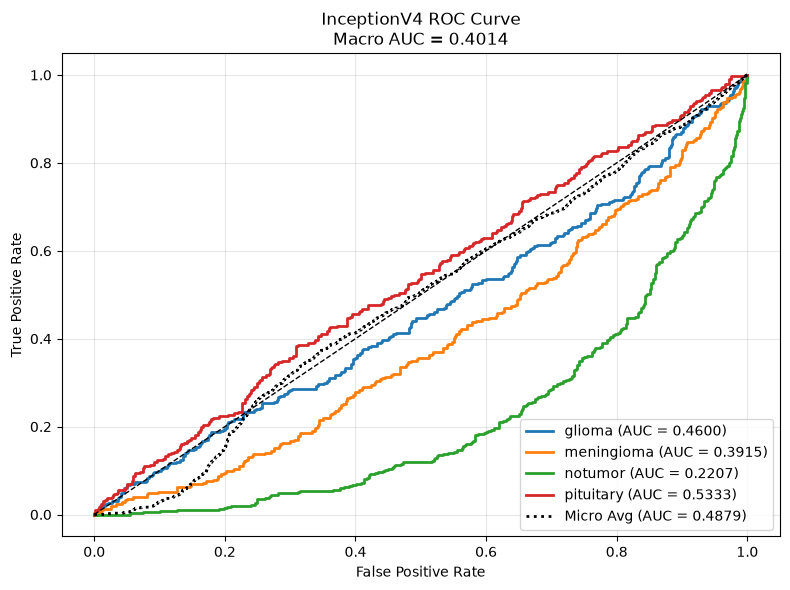


Per-Class AUC
glioma: 0.4600
meningioma: 0.3915
notumor: 0.2207
pituitary: 0.5333

Macro AUC : 0.4014
Micro AUC : 0.4879


In [12]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# -------------------------------
# Model already loaded as:
# inception
# -------------------------------

inception.eval()

all_probs = []
all_labels = []

for class_idx, class_name in enumerate(classes):

    class_path = os.path.join(test_dir, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    for img_name in image_files:

        img_path = os.path.join(
            class_path,
            img_name
        )

        image = Image.open(
            img_path
        ).convert("RGB")

        input_tensor = transform(
            image
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            outputs = inception(
                input_tensor
            )

            probs = torch.softmax(
                outputs,
                dim=1
            )[0].cpu().numpy()

        all_probs.append(probs)
        all_labels.append(class_idx)

# -------------------------------
# Convert
# -------------------------------

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

num_classes = len(classes)

y_true = label_binarize(
    all_labels,
    classes=list(range(num_classes))
)

# -------------------------------
# ROC
# -------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

macro_auc = roc_auc_score(
    y_true,
    all_probs,
    average='macro',
    multi_class='ovr'
)

fpr_micro, tpr_micro, _ = roc_curve(
    y_true.ravel(),
    all_probs.ravel()
)

micro_auc = auc(
    fpr_micro,
    tpr_micro
)

# -------------------------------
# Plot
# -------------------------------

plt.figure(figsize=(8,6))

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red'
]

for i, class_name in enumerate(classes):

    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        color=colors[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot(
    fpr_micro,
    tpr_micro,
    color='black',
    linestyle=':',
    lw=2,
    label=f"Micro Avg (AUC = {micro_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    'k--',
    lw=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"InceptionV4 ROC Curve\n"
    f"Macro AUC = {macro_auc:.4f}"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# -------------------------------
# Results
# -------------------------------

print("\nPer-Class AUC")

for i, class_name in enumerate(classes):
    print(f"{class_name}: {roc_auc[i]:.4f}")

print(f"\nMacro AUC : {macro_auc:.4f}")
print(f"Micro AUC : {micro_auc:.4f}")

In [45]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 3050 A Laptop GPU


In [46]:
import os
import json
import torch
import timm
import numpy as np
from tqdm import tqdm
from torch import nn, optim
from torch.amp import GradScaler, autocast
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, accuracy_score

# -----------------------------
# Paths
# -----------------------------
train_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Training_256x256"
test_dir  = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

# -----------------------------
# Device
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# -----------------------------
# Hyperparameters
# -----------------------------
LR = 1e-4
WD = 1e-4
BATCH_SIZE = 16
EPOCHS = 5

# -----------------------------
# Transforms
# -----------------------------
train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

# -----------------------------
# Dataset
# -----------------------------
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)

# -----------------------------
# Dataloaders
# -----------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# -----------------------------
# Model
# -----------------------------
model = timm.create_model(
    "inception_v4",
    pretrained=True,
    num_classes=num_classes
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WD
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

scaler = GradScaler("cuda")

# -----------------------------
# Training
# -----------------------------
best_acc = 0.0

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    pbar = tqdm(train_loader,
                desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, labels in pbar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        preds = outputs.argmax(1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_preds = []
    val_labels = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            preds = outputs.argmax(1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

    val_acc = accuracy_score(
        val_labels,
        val_preds
    ) * 100

    print(
        f"\nEpoch {epoch+1}"
        f" | Train Acc={train_acc:.2f}%"
        f" | Val Acc={val_acc:.2f}%"
    )

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            "inceptionv4_retrained_best.pth"
        )

        print("✅ Saved best model")

    scheduler.step()

print("\nBest Accuracy:", best_acc)

# -----------------------------
# Final Report
# -----------------------------
model.load_state_dict(
    torch.load(
        "inceptionv4_retrained_best.pth",
        map_location=device
    )
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=train_dataset.classes
    )
)

metrics = {
    "accuracy": round(best_acc, 2)
}

with open(
    "metrics_inceptionv4_retrained.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("✅ Saved metrics")

Using: cuda
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


c:\Users\Rashmitha R Nayak\anaconda3\envs\brain\Lib\site-packages\huggingface_hub\file_download.py:137: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Rashmitha R Nayak\.cache\huggingface\hub\models--timm--inception_v4.tf_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Epoch 1/5: 100%|██████████| 357/357 [01:55<00:00,  3.10it/s]



Epoch 1 | Train Acc=89.83% | Val Acc=97.48%
✅ Saved best model


Epoch 2/5: 100%|██████████| 357/357 [01:57<00:00,  3.03it/s]



Epoch 2 | Train Acc=97.23% | Val Acc=98.93%
✅ Saved best model


...


Epoch 4 | Train Acc=99.30% | Val Acc=99.24%
✅ Saved best model


Epoch 5/5: 100%|██████████| 357/357 [01:44<00:00,  3.41it/s]



Epoch 5 | Train Acc=99.74% | Val Acc=99.39%
✅ Saved best model

Best Accuracy: 99.38977879481313


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\529624106.py:215: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


              precision    recall  f1-score   support

      glioma       0.99      1.00      0.99       300
  meningioma       0.98      1.00      0.99       306
     notumor       1.00      0.99      0.99       405
   pituitary       1.00      1.00      1.00       300

    accuracy                           0.99      1311
   macro avg       0.99      0.99      0.99      1311
weighted avg       0.99      0.99      0.99      1311

✅ Saved metrics


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_2632\285171190.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


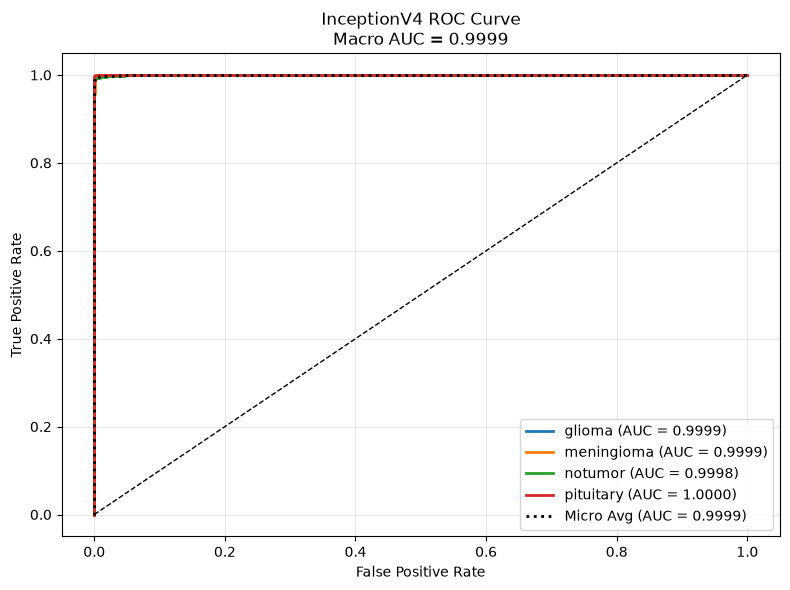


Per-Class AUC
glioma: 0.9999
meningioma: 0.9999
notumor: 0.9998
pituitary: 1.0000

Macro AUC : 0.9999
Micro AUC : 0.9999


In [47]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# ----------------------------------
# Load Best Retrained Model
# ----------------------------------

model.load_state_dict(
    torch.load(
        "inceptionv4_retrained_best.pth",
        map_location=device
    )
)

model.eval()

# ----------------------------------
# Collect Probabilities
# ----------------------------------

all_probs = []
all_labels = []

for class_idx, class_name in enumerate(train_dataset.classes):

    class_path = os.path.join(
        test_dir,
        class_name
    )

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    for img_name in image_files:

        img_path = os.path.join(
            class_path,
            img_name
        )

        image = Image.open(
            img_path
        ).convert("RGB")

        input_tensor = test_transform(
            image
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            outputs = model(
                input_tensor
            )

            probs = torch.softmax(
                outputs,
                dim=1
            )[0].cpu().numpy()

        all_probs.append(probs)
        all_labels.append(class_idx)

# ----------------------------------
# ROC Computation
# ----------------------------------

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

num_classes = len(train_dataset.classes)

y_true = label_binarize(
    all_labels,
    classes=list(range(num_classes))
)

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

macro_auc = roc_auc_score(
    y_true,
    all_probs,
    average="macro",
    multi_class="ovr"
)

fpr_micro, tpr_micro, _ = roc_curve(
    y_true.ravel(),
    all_probs.ravel()
)

micro_auc = auc(
    fpr_micro,
    tpr_micro
)

# ----------------------------------
# Plot
# ----------------------------------

plt.figure(figsize=(8,6))

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red'
]

for i, class_name in enumerate(train_dataset.classes):

    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        color=colors[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot(
    fpr_micro,
    tpr_micro,
    color='black',
    linestyle=':',
    lw=2,
    label=f"Micro Avg (AUC = {micro_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    'k--',
    lw=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"InceptionV4 ROC Curve\n"
    f"Macro AUC = {macro_auc:.4f}"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "inceptionv4_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------
# Results
# ----------------------------------

print("\nPer-Class AUC")

for i, class_name in enumerate(train_dataset.classes):
    print(f"{class_name}: {roc_auc[i]:.4f}")

print(f"\nMacro AUC : {macro_auc:.4f}")
print(f"Micro AUC : {micro_auc:.4f}")

In [1]:
import torch
import torch.nn as nn
import timm
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm import tqdm

c:\Users\Rashmitha R Nayak\anaconda3\envs\brain\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
])

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Classes:", test_dataset.classes)
print("Test Images:", len(test_dataset))

Using device: cuda
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test Images: 1311


In [3]:
model = timm.create_model(
    "inception_v4",
    pretrained=False,
    num_classes=len(test_dataset.classes)
)

model.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\inceptionv4\inceptionv4_retrained_best.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("InceptionV4 loaded successfully!")

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_14752\2792693852.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


InceptionV4 loaded successfully!


In [4]:
all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(device)

        outputs = model(images)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Inference completed!")

100%|██████████| 41/41 [00:32<00:00,  1.27it/s]

Inference completed!


In [5]:
import os

save_dir = r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\Statistical_Test"

os.makedirs(save_dir, exist_ok=True)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

np.save(
    os.path.join(save_dir, "inception_preds.npy"),
    all_preds
)

print("Saved successfully!")

print("Prediction Shape:", all_preds.shape)
print("Label Shape:", all_labels.shape)

Saved successfully!
Prediction Shape: (1311,)
Label Shape: (1311,)


In [6]:
print(all_preds[:20])
print(all_labels[:20])

print()

print("Total Predictions :", len(all_preds))
print("Total Labels      :", len(all_labels))

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Total Predictions : 1311
Total Labels      : 1311
